An example that shows three tallies. Since no geometry is specified, just use an example PWR pin cell.

In [1]:
%run -i clean_script.py
import openmc 
import numpy as np

Cell
	ID             =	1
	Name           =	Fuel
	Fill           =	Material 1
	Region         =	-1
	Rotation       =	None
	Temperature    =	None
	Density        =	None
	Translation    =	None
	Volume         =	None

Material
	ID             =	1
	Name           =	UO2 (2.4%)
	Temperature    =	None
	Density        =	10.29769 [g/cm3]
	Volume         =	None [cm^3]
	Depletable     =	True
	S(a,b) Tables  
	Nuclides       
	U234           =	4.4843e-06   [ao]
	U235           =	0.00055815   [ao]
	U238           =	0.022408     [ao]
	O16            =	0.045829     [ao]



<Axes: xlabel='x [cm]', ylabel='y [cm]'>

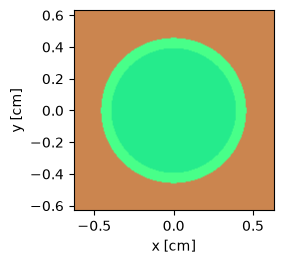

In [2]:
model = openmc.examples.pwr_pin_cell()
cells = [cell for cell in model.geometry.get_all_cells().values()]
materials = [mat for mat in model.materials]
print(cells[0])
print(materials[0])
model.plot()

In this example, we have a standard tally F4:N 1 which is a neutron fluence tally averaged over cell 1. 
There are 3 bins:
FM4 ( 1 (1 -4)(-2)) ( 1 1)
* The first bin is 1 1 -4. c = 1, material = 1, reaction is -4 (for neutron, this is avg. neutron heating (MeV/collision))
* The second is 1 1 -2     c = 1, material = 1, reaction is -2 (absorption cross section, so would be absorption rx rate)
* The third is 1 1         c = 1, material = 1. no rxn, so just raw fluence

In [3]:
import uncertainties

To do this in OpenMC, I would create a single tally with three separate scores: one for avg. neutron heating, another for the absorption and the last for flux. The only filter would be a cellfilter. The material filter is somewhat implied in that 

In [4]:
# Tally creation
f4_filter = openmc.CellFilter(bins=[cells[0]])
f4 = openmc.Tally(name="f4",scores=['heating','absorption','flux',],filters=[f4_filter])

tallies = openmc.Tallies(tallies=[f4])
model.tallies = tallies

In [5]:
settings = openmc.Settings()
settings.run_mode='eigenvalue'
settings.particles = 100
settings.batches = 20

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.Point((0,0,0))
source.angle = openmc.stats.Isotropic() 
settings.source = source

model.settings = settings

It would normally make sense to normalize w.r.t the pin power. The scheme would be to figure out how many source particles per unit time must be emitted, in order to reach an observed power eV/second. This can be done by doing a heating tally on the entire system (units of eV/source). 

After eigenvalue normalization, it also would make sense to normalize w.r.t. volume.

In [6]:
sp_filename = model.run(output=False)

with openmc.StatePoint(sp_filename) as sp:
    f4_tally = sp.get_tally(name='f4')
    df = f4_tally.get_pandas_dataframe()
    
    print(df)

   cell nuclide       score     mean  std. dev.
0     1   total     heating 7.91e+07   2.07e+06
1     1   total  absorption 8.13e-01   1.72e-02
2     1   total        flux 1.31e+01   1.14e-01
